<a href="https://colab.research.google.com/github/aljon04/CMSC-190Part2/blob/main/PArt%202.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import glob

# 1. Create directories if they don't exist
!mkdir -p /content/sen1floods11/S1Hand
!mkdir -p /content/sen1floods11/LabelHand

# 2. Download Hand-Labeled Sentinel-1 SAR imagery and Masks
print(" Downloading Sentinel-1 SAR images (S1Hand)...")
!gsutil -m cp gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/*.tif /content/sen1floods11/S1Hand/

print("\n Downloading Hand-Labeled Flood Masks (LabelHand)...")
!gsutil -m cp gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/*.tif /content/sen1floods11/LabelHand/

# 3. Verify file counts
s1_count = len(glob.glob("/content/sen1floods11/S1Hand/*.tif"))
label_count = len(glob.glob("/content/sen1floods11/LabelHand/*.tif"))

print("\n--- Download Verification ---")
print(f" Found {s1_count} SAR images in /content/sen1floods11/S1Hand")
print(f" Found {label_count} Mask images in /content/sen1floods11/LabelHand")

if s1_count == 0 or label_count == 0:
    print("Download failed. Check your internet connection or Google Colab session.")
else:
    print("Dataset successfully downloaded and ready for PyTorch!")

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_103757_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_195474_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_129334_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_23014_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_242570_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_290290_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_294583_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1

In [2]:
from google.colab import drive
drive.mount('/content/drive')

# Copy to Google Drive so it persists permanently
!mkdir -p /content/drive/MyDrive/sen1floods11_dataset
!cp -r /content/sen1floods11/* /content/drive/MyDrive/sen1floods11_dataset/
print(" Saved permanently to Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
 Saved permanently to Google Drive!


In [3]:
import torch
import torch.nn as nn


class AttentionGate(nn.Module):
  #Filters out irrelevant background noise from skip connections so the decoder can focus specifically on flood regions

  def __init__(self, F_g, F_l, F_int):
    super(AttentionGate, self).__init__()

    #trnsform the gating signal(fo the deeper decoder channels)
    self.W_g = nn.Sequential(
        nn.Conv2d(F_g, F_int, kernel_size=1, stride=1, padding=0, bias=True),
        nn.BatchNorm2d(F_int),
    )
    #trnsform the skip connection features
    self.W_x = nn.Sequential(
        nn.Conv2d(F_l, F_int, kernel_size=1, stride=1, padding=0, bias=True),
        nn.BatchNorm2d(F_int),
    )
    #compress combined features into a single channel attention map
    self.psi = nn.Sequential(
        nn.Conv2d(F_int, 1, kernel_size=1, stride=1, padding=0, bias=True),
        nn.BatchNorm2d(1),
        nn.Sigmoid(),
    )
    self.relu = nn.ReLU(inplace=True)

  def forward(self, g, x):
    g1 = self.W_g(g)
    x1 = self.W_x(x)
    psi = self.relu(g1 + x1)
    psi = self.psi(psi)
    return x * psi

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F


# 1. Double Convolution Block
class ConvBlock(nn.Module):

  def __init__(self, in_channels, out_channels):
    super(ConvBlock, self).__init__()
    self.conv = nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )

  def forward(self, x):
    return self.conv(x)


# 2. Attention Gate Module
class AttentionGate(nn.Module):

  def __init__(self, F_g, F_l, F_int):
    super(AttentionGate, self).__init__()
    self.W_g = nn.Sequential(
        nn.Conv2d(F_g, F_int, kernel_size=1, stride=1, padding=0, bias=True),
        nn.BatchNorm2d(F_int),
    )
    self.W_x = nn.Sequential(
        nn.Conv2d(F_l, F_int, kernel_size=1, stride=1, padding=0, bias=True),
        nn.BatchNorm2d(F_int),
    )
    self.psi = nn.Sequential(
        nn.Conv2d(F_int, 1, kernel_size=1, stride=1, padding=0, bias=True),
        nn.BatchNorm2d(1),
        nn.Sigmoid(),
    )
    self.relu = nn.ReLU(inplace=True)

  def forward(self, g, x):
    g1 = self.W_g(g)
    x1 = self.W_x(x)
    psi = self.relu(g1 + x1)
    psi = self.psi(psi)
    return x * psi


# 3. Full Attention U-Net
class AttentionUNet(nn.Module):

  def __init__(self, in_channels=2, out_channels=1):
    super(AttentionUNet, self).__init__()

    # Encoder
    self.conv1 = ConvBlock(in_channels, 64)
    self.pool1 = nn.MaxPool2d(2)

    self.conv2 = ConvBlock(64, 128)
    self.pool2 = nn.MaxPool2d(2)

    self.conv3 = ConvBlock(128, 256)
    self.pool3 = nn.MaxPool2d(2)

    self.conv4 = ConvBlock(256, 512)
    self.pool4 = nn.MaxPool2d(2)

    # Bottleneck
    self.bottleneck = ConvBlock(512, 1024)

    # Decoder with Attention Gates
    self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
    self.ag4 = AttentionGate(F_g=512, F_l=512, F_int=256)
    self.dec4 = ConvBlock(1024, 512)

    self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
    self.ag3 = AttentionGate(F_g=256, F_l=256, F_int=128)
    self.dec3 = ConvBlock(512, 256)

    self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
    self.ag2 = AttentionGate(F_g=128, F_l=128, F_int=64)
    self.dec2 = ConvBlock(256, 128)

    self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
    self.ag1 = AttentionGate(F_g=64, F_l=64, F_int=32)
    self.dec1 = ConvBlock(128, 64)

    # Output Layer
    self.final_conv = nn.Conv2d(64, out_channels, kernel_size=1)

  def forward(self, x):
    # Encoder
    e1 = self.conv1(x)
    e2 = self.conv2(self.pool1(e1))
    e3 = self.conv3(self.pool2(e2))
    e4 = self.conv4(self.pool3(e3))

    # Bottleneck
    b = self.bottleneck(self.pool4(e4))

    # Decoder
    d4 = self.up4(b)
    x4 = self.ag4(g=d4, x=e4)
    d4 = self.dec4(torch.cat((x4, d4), dim=1))

    d3 = self.up3(d4)
    x3 = self.ag3(g=d3, x=e3)
    d3 = self.dec3(torch.cat((x3, d3), dim=1))

    d2 = self.up2(d3)
    x2 = self.ag2(g=d2, x=e2)
    d2 = self.dec2(torch.cat((x2, d2), dim=1))

    d1 = self.up1(d2)
    x1 = self.ag1(g=d1, x=e1)
    d1 = self.dec1(torch.cat((x1, d1), dim=1))

    return self.final_conv(d1)  # Raw logits output

In [5]:
import glob
import os
import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset
import tifffile as tiff


class Sen1Floods11Dataset(Dataset):

  def __init__(self, s1_dir, label_dir):
    self.s1_files = sorted(glob.glob(os.path.join(s1_dir, "*.tif")))
    self.label_files = sorted(glob.glob(os.path.join(label_dir, "*.tif")))

    if not self.s1_files:
        raise FileNotFoundError(f"No SAR images found in {s1_dir}. Please ensure files are downloaded.")
    if not self.label_files:
        raise FileNotFoundError(f"No label images found in {label_dir}. Please ensure files are downloaded.")


  def __len__(self):
    return len(self.s1_files)

  def __getitem__(self, idx):
    # Load SAR image (VV, VH bands)
    sar_img = tiff.imread(self.s1_files[idx]).astype(np.float32)

    # Ensure shape is (Channels, Height, Width) -> (2, 512, 512)
    if sar_img.ndim == 3 and sar_img.shape[-1] == 2:
      sar_img = np.moveaxis(sar_img, -1, 0)

    # Normalize SAR values (-30 dB to 0 dB mapped to [0, 1])
    sar_img = np.clip(sar_img, -30.0, 0.0)
    sar_img = (sar_img + 30.0) / 30.0

    # Load Label Mask
    label_img = tiff.imread(self.label_files[idx]).astype(np.float32)

    # Convert invalid pixels (-1) to 0 (non-flood)
    label_img[label_img < 0] = 0.0

    # Convert to PyTorch Tensors
    x_tensor = torch.tensor(sar_img, dtype=torch.float32)
    y_tensor = torch.tensor(label_img, dtype=torch.float32).unsqueeze(
        0
    )  # Add channel dim: (1, H, W)

    return x_tensor, y_tensor


# Instantiate Dataset & DataLoader
dataset = Sen1Floods11Dataset(
    s1_dir="/content/sen1floods11/S1Hand",
    label_dir="/content/sen1floods11/LabelHand",
)

train_loader = DataLoader(dataset, batch_size=4, shuffle=True)

print(f"Dataset successfully initialized with {len(dataset)} samples!")

Dataset successfully initialized with 446 samples!


In [6]:
# Check GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running on device: {device}")

# Initialize model
model = AttentionUNet(in_channels=2, out_channels=1).to(device)

# Grab 1 batch from the DataLoader
images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)

# Pass through Attention U-Net
outputs = model(images)

print(f"Input Batch Shape:  {images.shape}")  # Should be [4, 2, 512, 512]
print(f" Label Batch Shape:  {labels.shape}")  # Should be [4, 1, 512, 512]
print(f" Output Batch Shape: {outputs.shape}")  # Should be [4, 1, 512, 512]
print("\n Model and DataLoader architecture verified! Ready for training.")

Running on device: cuda
Input Batch Shape:  torch.Size([4, 2, 512, 512])
 Label Batch Shape:  torch.Size([4, 1, 512, 512])
 Output Batch Shape: torch.Size([4, 1, 512, 512])

 Model and DataLoader architecture verified! Ready for training.


In [7]:
import torch
from torch.utils.data import DataLoader, random_split

# 1. Create full dataset
full_dataset = Sen1Floods11Dataset(
    s1_dir="/content/sen1floods11/S1Hand",
    label_dir="/content/sen1floods11/LabelHand",
)

# 2. Perform 80/20 reproducible split
train_size = int(0.80 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42),
)

# 3. Create DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=4, shuffle=True, num_workers=2
)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=2)

print(
    f"Split Complete: {len(train_dataset)} Train samples | {len(val_dataset)}"
    " Validation samples"
)

Split Complete: 356 Train samples | 90 Validation samples


In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F


# Combined Loss Function: BCE + Dice Loss
class DiceBCELoss(nn.Module):

  def __init__(self, smooth=1e-5):
    super(DiceBCELoss, self).__init__()
    self.smooth = smooth

  def forward(self, logits, targets):
    probs = torch.sigmoid(logits)

    # Flatten tensors
    probs_flat = probs.view(-1)
    targets_flat = targets.view(-1)

    # Compute BCE Loss
    bce_loss = F.binary_cross_entropy(probs_flat, targets_flat, reduction="mean")

    # Compute Dice Loss
    intersection = (probs_flat * targets_flat).sum()
    dice_score = (2.0 * intersection + self.smooth) / (
        probs_flat.sum() + targets_flat.sum() + self.smooth
    )
    dice_loss = 1.0 - dice_score

    return bce_loss + dice_loss


# Metric Functions for Evaluation (IoU & Dice)
def evaluate_metrics(logits, targets, threshold=0.5):
  probs = torch.sigmoid(logits)
  preds = (probs > threshold).float()

  preds_flat = preds.view(-1)
  targets_flat = targets.view(-1)

  intersection = (preds_flat * targets_flat).sum().item()
  total_preds = preds_flat.sum().item()
  total_targets = targets_flat.sum().item()

  union = total_preds + total_targets - intersection

  iou = (intersection + 1e-5) / (union + 1e-5)
  dice = (2.0 * intersection + 1e-5) / (total_preds + total_targets + 1e-5)

  return iou, dice


criterion = DiceBCELoss()
print("Loss function and metric evaluation methods initialized!")

Loss function and metric evaluation methods initialized!


In [9]:
import os
import random
import numpy as np
import torch
import torch.nn as nn


def seed_everything(seed=42):
  random.seed(seed)
  # Set seed for Python's built-in random module and OS hash environment
  os.environ['PYTHONHASHSEED'] = str(seed)
  # Set seed for NumPy random operations
  np.random.seed(seed)
  # Set seed for PyTorch on both CPU and all available GPUs
  torch.manual_seed(seed)
  torch.cuda.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)
  torch.backends.cudnn.deterministic = True
  torch.backends.cudnn.benchmark = False
  print(f'Seed set to {seed} for reproducible training.')


seed_everything(42)

Seed set to 42 for reproducible training.


In [10]:
class BCEDiceLoss(nn.Module):
  """
    Hybrid loss function combining Binary Cross-Entropy (BCE) and Soft Dice Loss.
    Balances pixel-wise classification accuracy (BCE) with region overlap (Dice)
    to handle class imbalance between flooded and non-flooded pixels.
    """

  def __init__(self, alpha=0.5):
    super().__init__()
    # Weighting factor balancing BCE and Dice losses (0.5 = equal weight)
    self.alpha = alpha
    # Combines Sigmoid activation and BCE loss in one numerically stable layer
    self.bce = nn.BCEWithLogitsLoss()

  def forward(self, inputs, targets):
    # 1. Compute pixel-wise Binary Cross-Entropy loss from raw model
    bce_loss = self.bce(inputs, targets)
    # 2. Apply Sigmoid to convert raw logits into probabilities [0, 1]
    probs = torch.sigmoid(inputs)
    probs = probs.view(-1)
    targets = targets.view(-1)

    intersection = (probs * targets).sum()
    dice_loss = 1 - (
        (2.0 * intersection + 1e-6) / (probs.sum() + targets.sum() + 1e-6)
    )

    return self.alpha * bce_loss + (1 - self.alpha) * dice_loss


def init_weights(m):
  """
    Custom weight initialization function applied recursively to model layers
    to stabilize gradient flow at the start of training.
    """
  if isinstance(m, nn.Conv2d) or isinstance(m, nn.ConvTranspose2d):
    nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
    if m.bias is not None:
      nn.init.constant_(m.bias, 0)
  elif isinstance(m, nn.BatchNorm2d):
    nn.init.constant_(m.weight, 1)
    nn.init.constant_(m.bias, 0)


criterion = BCEDiceLoss(alpha=0.5)
print('Loss function and weight initializers ready.')

Loss function and weight initializers ready.


In [12]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Instantiate models
std_model = StandardUNet(in_channels=2, out_channels=1).to(device)
att_model = AttentionUNet(in_channels=2, out_channels=1).to(device)

# Apply stable initial weights
std_model.apply(init_weights)
att_model.apply(init_weights)

# Set up optimizers and learning rate schedulers
optimizer_std = torch.optim.AdamW(
    std_model.parameters(), lr=1e-4, weight_decay=1e-4
)
optimizer_att = torch.optim.AdamW(
    att_model.parameters(), lr=1e-4, weight_decay=1e-4
)

scheduler_std = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_std, T_max=50
)
scheduler_att = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_att, T_max=50
)

print('Models instantiated, weights initialized, and optimizers ready.')

Models instantiated, weights initialized, and optimizers ready.


In [11]:
import glob
import os
import time
import numpy as np
import tifffile as tiff
import torch
import torch.nn as nn
from google.colab import drive
from torch.utils.data import DataLoader, Dataset, random_split

# ---------------------------------------------------------
# 1. MOUNT GOOGLE DRIVE & SET PERMANENT WEIGHTS DIRECTORY
# ---------------------------------------------------------
drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/flood_detection/weights'
os.makedirs(SAVE_DIR, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device ready: {device}')
print(f'Permanent weights directory: {SAVE_DIR}')


# ---------------------------------------------------------
# 2. SHARED BUILDING BLOCKS & ARCHITECTURES
# ---------------------------------------------------------
class ConvBlock(nn.Module):

  def __init__(self, in_channels, out_channels):
    super(ConvBlock, self).__init__()
    self.conv = nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )

  def forward(self, x):
    return self.conv(x)


class AttentionGate(nn.Module):

  def __init__(self, F_g, F_l, F_int):
    super(AttentionGate, self).__init__()
    self.W_g = nn.Sequential(
        nn.Conv2d(F_g, F_int, kernel_size=1, stride=1, padding=0, bias=True),
        nn.BatchNorm2d(F_int),
    )
    self.W_x = nn.Sequential(
        nn.Conv2d(F_l, F_int, kernel_size=1, stride=1, padding=0, bias=True),
        nn.BatchNorm2d(F_int),
    )
    self.psi = nn.Sequential(
        nn.Conv2d(F_int, 1, kernel_size=1, stride=1, padding=0, bias=True),
        nn.BatchNorm2d(1),
        nn.Sigmoid(),
    )
    self.relu = nn.ReLU(inplace=True)

  def forward(self, g, x):
    g1 = self.W_g(g)
    x1 = self.W_x(x)
    psi = self.relu(g1 + x1)
    return x * self.psi(psi)


class StandardUNet(nn.Module):

  def __init__(self, in_channels=2, out_channels=1):
    super(StandardUNet, self).__init__()
    self.conv1 = ConvBlock(in_channels, 64)
    self.pool1 = nn.MaxPool2d(2)
    self.conv2 = ConvBlock(64, 128)
    self.pool2 = nn.MaxPool2d(2)
    self.conv3 = ConvBlock(128, 256)
    self.pool3 = nn.MaxPool2d(2)
    self.conv4 = ConvBlock(256, 512)
    self.pool4 = nn.MaxPool2d(2)
    self.bottleneck = ConvBlock(512, 1024)

    self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
    self.dec4 = ConvBlock(1024, 512)
    self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
    self.dec3 = ConvBlock(512, 256)
    self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
    self.dec2 = ConvBlock(256, 128)
    self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
    self.dec1 = ConvBlock(128, 64)
    self.final_conv = nn.Conv2d(64, out_channels, kernel_size=1)

  def forward(self, x):
    e1 = self.conv1(x)
    e2 = self.conv2(self.pool1(e1))
    e3 = self.conv3(self.pool2(e2))
    e4 = self.conv4(self.pool3(e3))
    b = self.bottleneck(self.pool4(e4))

    d4 = self.dec4(torch.cat((e4, self.up4(b)), dim=1))
    d3 = self.dec3(torch.cat((e3, self.up3(d4)), dim=1))
    d2 = self.dec2(torch.cat((e2, self.up2(d3)), dim=1))
    d1 = self.dec1(torch.cat((e1, self.up1(d2)), dim=1))
    return self.final_conv(d1)


class AttentionUNet(nn.Module):

  def __init__(self, in_channels=2, out_channels=1):
    super(AttentionUNet, self).__init__()
    self.conv1 = ConvBlock(in_channels, 64)
    self.pool1 = nn.MaxPool2d(2)
    self.conv2 = ConvBlock(64, 128)
    self.pool2 = nn.MaxPool2d(2)
    self.conv3 = ConvBlock(128, 256)
    self.pool3 = nn.MaxPool2d(2)
    self.conv4 = ConvBlock(256, 512)
    self.pool4 = nn.MaxPool2d(2)
    self.bottleneck = ConvBlock(512, 1024)

    self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
    self.ag4 = AttentionGate(F_g=512, F_l=512, F_int=256)
    self.dec4 = ConvBlock(1024, 512)

    self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
    self.ag3 = AttentionGate(F_g=256, F_l=256, F_int=128)
    self.dec3 = ConvBlock(512, 256)

    self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
    self.ag2 = AttentionGate(F_g=128, F_l=128, F_int=64)
    self.dec2 = ConvBlock(256, 128)

    self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
    self.ag1 = AttentionGate(F_g=64, F_l=64, F_int=32)
    self.dec1 = ConvBlock(128, 64)
    self.final_conv = nn.Conv2d(64, out_channels, kernel_size=1)

  def forward(self, x):
    e1 = self.conv1(x)
    e2 = self.conv2(self.pool1(e1))
    e3 = self.conv3(self.pool2(e2))
    e4 = self.conv4(self.pool3(e3))
    b = self.bottleneck(self.pool4(e4))

    d4 = self.up4(b)
    d4 = self.dec4(torch.cat((self.ag4(g=d4, x=e4), d4), dim=1))

    d3 = self.up3(d4)
    d3 = self.dec3(torch.cat((self.ag3(g=d3, x=e3), d3), dim=1))

    d2 = self.up2(d3)
    d2 = self.dec2(torch.cat((self.ag2(g=d2, x=e2), d2), dim=1))

    d1 = self.up1(d2)
    d1 = self.dec1(torch.cat((self.ag1(g=d1, x=e1), d1), dim=1))

    return self.final_conv(d1)


# ---------------------------------------------------------
# 3. DATASET & LOSS DEFINITIONS
# ---------------------------------------------------------
class Sen1Floods11Dataset(Dataset):

  def __init__(self, s1_dir, label_dir):
    self.s1_files = sorted(glob.glob(os.path.join(s1_dir, '*.tif')))
    self.label_files = sorted(glob.glob(os.path.join(label_dir, '*.tif')))

  def __len__(self):
    return len(self.s1_files)

  def __getitem__(self, idx):
    sar_img = tiff.imread(self.s1_files[idx]).astype(np.float32)
    sar_img = np.nan_to_num(sar_img, nan=-30.0, posinf=0.0, neginf=-30.0)

    if sar_img.ndim == 3 and sar_img.shape[-1] == 2:
      sar_img = np.moveaxis(sar_img, -1, 0)

    sar_img = np.clip(sar_img, -30.0, 0.0)
    sar_img = (sar_img + 30.0) / 30.0

    label_img = tiff.imread(self.label_files[idx]).astype(np.float32)
    label_img = np.nan_to_num(label_img, nan=0.0)
    binary_label = (label_img == 1.0).astype(np.float32)

    return torch.from_numpy(sar_img), torch.from_numpy(binary_label).unsqueeze(0)


class StableDiceBCELoss(nn.Module):

  def __init__(self, smooth=1e-5):
    super(StableDiceBCELoss, self).__init__()
    self.smooth = smooth
    self.bce_logits = nn.BCEWithLogitsLoss()

  def forward(self, logits, targets):
    bce = self.bce_logits(logits, targets)
    probs = torch.sigmoid(logits)
    probs_flat = probs.view(-1)
    targets_flat = targets.view(-1)

    intersection = (probs_flat * targets_flat).sum()
    dice_score = (2.0 * intersection + self.smooth) / (
        probs_flat.sum() + targets_flat.sum() + self.smooth
    )
    return bce + (1.0 - dice_score)


def evaluate_metrics(logits, targets, threshold=0.5):
  probs = torch.sigmoid(logits)
  preds = (probs > threshold).float()

  preds_flat, targets_flat = preds.view(-1), targets.view(-1)
  intersection = (preds_flat * targets_flat).sum().item()
  total_preds = preds_flat.sum().item()
  total_targets = targets_flat.sum().item()
  union = total_preds + total_targets - intersection

  iou = (intersection + 1e-5) / (union + 1e-5)
  dice = (2.0 * intersection + 1e-5) / (total_preds + total_targets + 1e-5)
  return iou, dice

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device ready: cuda
Permanent weights directory: /content/drive/MyDrive/flood_detection/weights


In [13]:
std_weights_path = os.path.join(SAVE_DIR, 'best_standard_unet.pth')

if os.path.exists(std_weights_path):
  print(
      f'Standard U-Net weights already exist at: {std_weights_path}\nSkipping'
      ' training!'
  )
else:
  full_dataset = Sen1Floods11Dataset(
      s1_dir='/content/sen1floods11/S1Hand',
      label_dir='/content/sen1floods11/LabelHand',
  )

  train_size = int(0.80 * len(full_dataset))
  val_size = len(full_dataset) - train_size
  train_dataset, val_dataset = random_split(
      full_dataset,
      [train_size, val_size],
      generator=torch.Generator().manual_seed(42),
  )

  train_loader = DataLoader(
      train_dataset, batch_size=4, shuffle=True, num_workers=2
  )
  val_loader = DataLoader(
      val_dataset, batch_size=4, shuffle=False, num_workers=2
  )

  std_model = StandardUNet(in_channels=2, out_channels=1).to(device)
  optimizer = torch.optim.Adam(std_model.parameters(), lr=1e-4)
  criterion = StableDiceBCELoss()

  EPOCHS = 20
  best_val_loss = float('inf')

  print('Starting Standard U-Net Training...\n')

  for epoch in range(EPOCHS):
    start_time = time.time()

    std_model.train()
    train_loss, train_iou = 0.0, 0.0
    for images, labels in train_loader:
      images, labels = images.to(device), labels.to(device)
      optimizer.zero_grad()
      outputs = std_model(images)
      loss = criterion(outputs, labels)
      loss.backward()
      optimizer.step()

      train_loss += loss.item()
      iou, _ = evaluate_metrics(outputs, labels)
      train_iou += iou

    train_loss /= len(train_loader)
    train_iou /= len(train_loader)

    std_model.eval()
    val_loss, val_iou = 0.0, 0.0
    with torch.no_grad():
      for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = std_model(images)
        loss = criterion(outputs, labels)
        val_loss += loss.item()
        iou, _ = evaluate_metrics(outputs, labels)
        val_iou += iou

    val_loss /= len(val_loader)
    val_iou /= len(val_loader)
    elapsed = time.strftime('%M:%S', time.gmtime(time.time() - start_time))

    if val_loss < best_val_loss:
      best_val_loss = val_loss
      torch.save(std_model.state_dict(), std_weights_path)
      save_status = f'💾 Saved to Drive ({std_weights_path})'
    else:
      save_status = ''

    print(
        f'Epoch [{epoch+1:02d}/{EPOCHS:02d}] ({elapsed}) | Train Loss:'
        f' {train_loss:.4f} | Train IoU: {train_iou:.4f} | Val Loss:'
        f' {val_loss:.4f} | Val IoU: {val_iou:.4f} {save_status}'
    )

  print('\nStandard U-Net Training Complete!')

Standard U-Net weights already exist at: /content/drive/MyDrive/flood_detection/weights/best_standard_unet.pth
Skipping training!


In [15]:
att_weights_path = os.path.join(SAVE_DIR, 'best_attention_unet.pth')

full_dataset = Sen1Floods11Dataset(
    s1_dir='/content/sen1floods11/S1Hand',
    label_dir='/content/sen1floods11/LabelHand',
)

train_size = int(0.80 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(
    full_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42),
)

train_loader = DataLoader(
    train_dataset, batch_size=4, shuffle=True, num_workers=2
)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=2)

att_model = AttentionUNet(in_channels=2, out_channels=1).to(device)
optimizer = torch.optim.Adam(att_model.parameters(), lr=1e-4)
criterion = StableDiceBCELoss()

# Check if pre-existing weights exist to resume training or skip
if os.path.exists(att_weights_path):
  print(f'Found existing weights at: {att_weights_path}')
  att_model.load_state_dict(
      torch.load(att_weights_path, map_location=device, weights_only=True)
  )
  best_val_loss = 0.7018  # Best val loss recorded from previous run
  print('Loaded existing weights. Resuming training...\n')
else:
  best_val_loss = float('inf')
  print('Starting Attention U-Net Training from scratch...\n')

EPOCHS = 20  # Set desired training epochs

for epoch in range(EPOCHS):
  start_time = time.time()

  att_model.train()
  train_loss, train_iou = 0.0, 0.0
  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad()
    outputs = att_model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    train_loss += loss.item()
    iou, _ = evaluate_metrics(outputs, labels)
    train_iou += iou

  train_loss /= len(train_loader)
  train_iou /= len(train_loader)

  att_model.eval()
  val_loss, val_iou = 0.0, 0.0
  with torch.no_grad():
    for images, labels in val_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = att_model(images)
      loss = criterion(outputs, labels)
      val_loss += loss.item()
      iou, _ = evaluate_metrics(outputs, labels)
      val_iou += iou

  val_loss /= len(val_loader)
  val_iou /= len(val_loader)
  elapsed = time.strftime('%M:%S', time.gmtime(time.time() - start_time))

  if val_loss < best_val_loss:
    best_val_loss = val_loss
    torch.save(att_model.state_dict(), att_weights_path)
    save_status = f'New Best Saved to Drive ({att_weights_path})'
  else:
    save_status = ''

  print(
      f'Epoch [{epoch+1:02d}/{EPOCHS:02d}] ({elapsed}) | Train Loss:'
      f' {train_loss:.4f} | Train IoU: {train_iou:.4f} | Val Loss:'
      f' {val_loss:.4f} | Val IoU: {val_iou:.4f} {save_status}'
  )

print('\nAttention U-Net Training Run Complete!')

Found existing weights at: /content/drive/MyDrive/flood_detection/weights/best_attention_unet.pth
Loaded existing weights. Resuming training...

Epoch [01/20] (02:05) | Train Loss: 0.5615 | Train IoU: 0.4946 | Val Loss: 0.6314 | Val IoU: 0.4236 New Best Saved to Drive (/content/drive/MyDrive/flood_detection/weights/best_attention_unet.pth)
Epoch [02/20] (02:11) | Train Loss: 0.5483 | Train IoU: 0.5018 | Val Loss: 0.5980 | Val IoU: 0.4744 New Best Saved to Drive (/content/drive/MyDrive/flood_detection/weights/best_attention_unet.pth)
Epoch [03/20] (02:11) | Train Loss: 0.5667 | Train IoU: 0.4836 | Val Loss: 0.6167 | Val IoU: 0.4480 
Epoch [04/20] (02:11) | Train Loss: 0.5439 | Train IoU: 0.5127 | Val Loss: 0.6030 | Val IoU: 0.4731 
Epoch [05/20] (02:11) | Train Loss: 0.5435 | Train IoU: 0.5064 | Val Loss: 0.5948 | Val IoU: 0.4733 New Best Saved to Drive (/content/drive/MyDrive/flood_detection/weights/best_attention_unet.pth)
Epoch [06/20] (02:11) | Train Loss: 0.5503 | Train IoU: 0.5086

In [ ]:
# Direct paths to Google Drive saved weights
std_weights_path = os.path.join(SAVE_DIR, 'best_standard_unet.pth')
att_weights_path = os.path.join(SAVE_DIR, 'best_attention_unet.pth')

# Load Standard U-Net
std_model = StandardUNet(in_channels=2, out_channels=1).to(device)
if os.path.exists(std_weights_path):
  std_model.load_state_dict(
      torch.load(std_weights_path, map_location=device, weights_only=True)
  )
  std_model.eval()
  print(f'Standard U-Net successfully loaded from: {std_weights_path}')
else:
  print(f'Standard U-Net weights not found at: {std_weights_path}')

# Load Attention U-Net
att_model = AttentionUNet(in_channels=2, out_channels=1).to(device)
if os.path.exists(att_weights_path):
  att_model.load_state_dict(
      torch.load(att_weights_path, map_location=device, weights_only=True)
  )
  att_model.eval()
  print(f'Attention U-Net successfully loaded from: {att_weights_path}')
else:
  print(f'Attention U-Net weights not found at: {att_weights_path}')

In [1]:
import glob
import os
import numpy as np
import torch
import tifffile as tiff
from torch.utils.data import Dataset, DataLoader

class Sen1Floods11Dataset(Dataset):
    def __init__(self, s1_dir, label_dir):
        self.s1_files = sorted(glob.glob(os.path.join(s1_dir, "*.tif")))
        self.label_files = sorted(glob.glob(os.path.join(label_dir, "*.tif")))

    def __len__(self):
        return len(self.s1_files)

    def __getitem__(self, idx):
        # Load SAR image
        sar_img = tiff.imread(self.s1_files[idx]).astype(np.float32)

        # 1. Clean NaNs and Infs in SAR data
        sar_img = np.nan_to_num(sar_img, nan=-30.0, posinf=0.0, neginf=-30.0)

        # Ensure (Channels, Height, Width) -> (2, 512, 512)
        if sar_img.ndim == 3 and sar_img.shape[-1] == 2:
            sar_img = np.moveaxis(sar_img, -1, 0)

        # Normalize SAR (-30 dB to 0 dB mapped to [0, 1])
        sar_img = np.clip(sar_img, -30.0, 0.0)
        sar_img = (sar_img + 30.0) / 30.0

        # Load Label Mask
        label_img = tiff.imread(self.label_files[idx]).astype(np.float32)
        label_img = np.nan_to_num(label_img, nan=0.0)

        # 2. Force binary ground truth strictly to 0.0 or 1.0 (removes -1 invalid pixels)
        label_img = (label_img == 1.0).astype(np.float32)

        # Convert to PyTorch Tensors
        x_tensor = torch.from_numpy(sar_img)
        y_tensor = torch.from_numpy(label_img).unsqueeze(0) # (1, H, W)

        return x_tensor, y_tensor

In [ ]:
import torch
import torch.nn as nn

class DiceBCELoss(nn.Module):
    def __init__(self, smooth=1e-5):
        super(DiceBCELoss, self).__init__()
        self.smooth = smooth
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, targets):
        # Numerically stable BCE
        bce_loss = self.bce(logits, targets)

        # Sigmoid for Dice calculation
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(-1)
        targets_flat = targets.view(-1)

        intersection = (probs_flat * targets_flat).sum()
        dice_score = (2.0 * intersection + self.smooth) / (
            probs_flat.sum() + targets_flat.sum() + self.smooth
        )
        dice_loss = 1.0 - dice_score

        return bce_loss + dice_loss

 Loaded model weights from: /content/drive/MyDrive/flood_detection/weights/best_attention_unet.pth


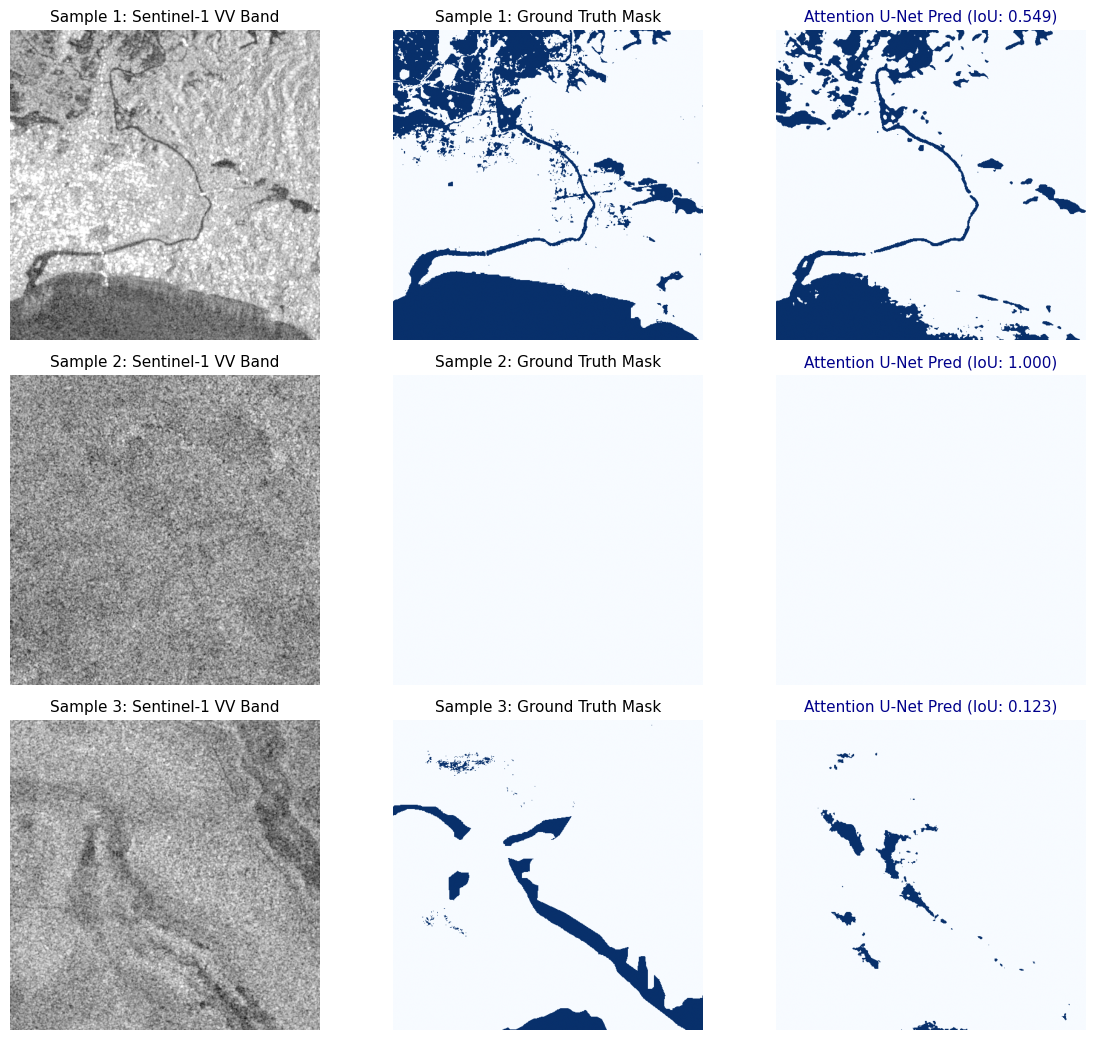

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import torch
from google.colab import drive

# 1. ENSURE DRIVE MOUNT & LOCATE WEIGHTS
if not os.path.exists('/content/drive'):
  drive.mount('/content/drive')


def find_weights_file(filename):
  search_paths = [
      '/content/drive/MyDrive/flood_detection/weights',
      '/content/drive/MyDrive/flood_detection',
      '/content',
  ]
  for path in search_paths:
    full_path = os.path.join(path, filename)
    if os.path.exists(full_path):
      return full_path

  for root, _, files in os.walk('/content'):
    if filename in files:
      return os.path.join(root, filename)

  raise FileNotFoundError(
      f" Could not find '{filename}'. Check if Cell 1 / Google Drive is"
      ' mounted.'
  )


# 2. LOAD ATTENTION U-NET WEIGHTS FROM DRIVE
att_weights_path = find_weights_file('best_attention_unet.pth')
print(f' Loaded model weights from: {att_weights_path}')

model = AttentionUNet(in_channels=2, out_channels=1).to(device)
model.load_state_dict(
    torch.load(att_weights_path, map_location=device, weights_only=True)
)
model.eval()

# 3. GET A BATCH FROM VALIDATION SET
val_iter = iter(val_loader)
images, labels = next(val_iter)
images, labels = images.to(device), labels.to(device)

# 4. GENERATE PREDICTIONS WITH STANDARD THRESHOLD
THRESHOLD = 0.35

with torch.no_grad():
  outputs = model(images)
  probs = torch.sigmoid(outputs)
  preds = (probs > THRESHOLD).float()

# 5. PLOT SAMPLES SIDE-BY-SIDE
num_samples = min(3, images.size(0))
fig, axes = plt.subplots(num_samples, 3, figsize=(12, 3.5 * num_samples))

for i in range(num_samples):
  sar_vv = images[i, 0].cpu().numpy()
  gt_mask = labels[i, 0].cpu().numpy()
  pred_mask = preds[i, 0].cpu().numpy()

  # Calculate IoU metric per sample
  intersection = (pred_mask * gt_mask).sum()
  union = pred_mask.sum() + gt_mask.sum() - intersection
  sample_iou = (intersection + 1e-5) / (union + 1e-5)

  # Column 1: SAR VV Band
  axes[i, 0].imshow(sar_vv, cmap='gray')
  axes[i, 0].set_title(f'Sample {i+1}: Sentinel-1 VV Band', fontsize=11)
  axes[i, 0].axis('off')

  # Column 2: Ground Truth
  axes[i, 1].imshow(gt_mask, cmap='Blues')
  axes[i, 1].set_title(f'Sample {i+1}: Ground Truth Mask', fontsize=11)
  axes[i, 1].axis('off')

  # Column 3: Attention U-Net Prediction
  axes[i, 2].imshow(pred_mask, cmap='Blues')
  axes[i, 2].set_title(
      f'Attention U-Net Pred (IoU: {sample_iou:.3f})',
      fontsize=11,
      color='darkblue',
  )
  axes[i, 2].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import torch
from google.colab import drive

# ---------------------------------------------------------
# 1. MOUNT DRIVE & LOCATE WEIGHTS
# ---------------------------------------------------------
if not os.path.exists('/content/drive'):
  drive.mount('/content/drive')


def find_weights_file(filename):
  search_paths = [
      '/content/drive/MyDrive/flood_detection/weights',
      '/content/drive/MyDrive/flood_detection',
      '/content',
  ]
  for path in search_paths:
    full_path = os.path.join(path, filename)
    if os.path.exists(full_path):
      return full_path

  for root, _, files in os.walk('/content'):
    if filename in files:
      return os.path.join(root, filename)

  raise FileNotFoundError(
      f" Could not find '{filename}'. Ensure model training has run or Drive"
      ' is mounted.'
  )


# ---------------------------------------------------------
# 2. LOAD BOTH MODELS SAFELY
# ---------------------------------------------------------
att_weights_path = find_weights_file('best_attention_unet.pth')
std_weights_path = find_weights_file('best_standard_unet.pth')

att_model = AttentionUNet(in_channels=2, out_channels=1).to(device)
att_model.load_state_dict(
    torch.load(att_weights_path, map_location=device, weights_only=True)
)
att_model.eval()

std_model = StandardUNet(in_channels=2, out_channels=1).to(device)
std_model.load_state_dict(
    torch.load(std_weights_path, map_location=device, weights_only=True)
)
std_model.eval()

print(f'Standard U-Net loaded from: {std_weights_path}')
print(f'Attention U-Net loaded from: {att_weights_path}')

# ---------------------------------------------------------
# 3. GRAB VALIDATION BATCH & PREDICT
# ---------------------------------------------------------
# Threshold fixed from 0.20 to 0.50 to prevent false positives in Standard U-Net
THRESHOLD = 0.35

images, labels = next(iter(val_loader))
images, labels = images.to(device), labels.to(device)

with torch.no_grad():
  std_preds = (torch.sigmoid(std_model(images)) > THRESHOLD).float()
  att_preds = (torch.sigmoid(att_model(images)) > THRESHOLD).float()

# ---------------------------------------------------------
# 4. PLOT 4-COLUMN COMPARISON GRID
# ---------------------------------------------------------
num_samples = min(3, images.size(0))
fig, axes = plt.subplots(num_samples, 4, figsize=(16, 3.8 * num_samples))

for i in range(num_samples):
  sar_vv = images[i, 0].cpu().numpy()
  gt_mask = labels[i, 0].cpu().numpy()
  std_mask = std_preds[i, 0].cpu().numpy()
  att_mask = att_preds[i, 0].cpu().numpy()

  # Compute IoUs
  std_intersection = (std_mask * gt_mask).sum()
  std_union = std_mask.sum() + gt_mask.sum() - std_intersection
  std_iou = (std_intersection + 1e-5) / (std_union + 1e-5)

  att_intersection = (att_mask * gt_mask).sum()
  att_union = att_mask.sum() + gt_mask.sum() - att_intersection
  att_iou = (att_intersection + 1e-5) / (att_union + 1e-5)

  # Column 1: SAR VV Input
  axes[i, 0].imshow(sar_vv, cmap='gray')
  axes[i, 0].set_title(f'Sample {i+1}: Sentinel-1 VV', fontsize=11)
  axes[i, 0].axis('off')

  # Column 2: Ground Truth
  axes[i, 1].imshow(gt_mask, cmap='Blues')
  axes[i, 1].set_title('Ground Truth Mask', fontsize=11)
  axes[i, 1].axis('off')

  # Column 3: Standard U-Net Prediction
  axes[i, 2].imshow(std_mask, cmap='Blues')
  axes[i, 2].set_title(
      f'Standard U-Net\n(IoU: {std_iou:.3f})', fontsize=11, color='darkblue'
  )
  axes[i, 2].axis('off')

  # Column 4: Attention U-Net Prediction
  axes[i, 3].imshow(att_mask, cmap='Blues')
  axes[i, 3].set_title(
      f'Attention U-Net\n(IoU: {att_iou:.3f})', fontsize=11, color='darkblue'
  )
  axes[i, 3].axis('off')

plt.tight_layout()
plt.show()

In [ ]:

import glob
import os
import matplotlib.pyplot as plt
import numpy as np
import tifffile as tiff
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, random_split

# ---------------------------------------------------------
# 0. GOOGLE DRIVE MOUNT (Optional - Uncomment if accessing Drive in Colab)
# ---------------------------------------------------------
# from google.colab import drive
# drive.mount('/content/drive')

# Update these paths to match where your .pth files are stored
STANDARD_WEIGHTS = "/content/drive/MyDrive/flood_detection/weights/best_standard_unet.pth"
ATTENTION_WEIGHTS = "/content/drive/MyDrive/flood_detection/weights/best_attention_unet.pth"

# ---------------------------------------------------------
# 1. SETUP & DEVICE CONFIGURATION
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f" Running Evaluation & Visualization on: {device}")


# ---------------------------------------------------------
# 2. DATASET DEFINITION
# ---------------------------------------------------------
class Sen1Floods11Dataset(Dataset):

    def __init__(self, s1_dir, label_dir):
        self.s1_files = sorted(glob.glob(os.path.join(s1_dir, "*.tif")))
        self.label_files = sorted(glob.glob(os.path.join(label_dir, "*.tif")))

    def __len__(self):
        return len(self.s1_files)

    def __getitem__(self, idx):
        sar_img = tiff.imread(self.s1_files[idx]).astype(np.float32)
        sar_img = np.nan_to_num(sar_img, nan=-30.0, posinf=0.0, neginf=-30.0)

        if sar_img.ndim == 3 and sar_img.shape[-1] == 2:
            sar_img = np.moveaxis(sar_img, -1, 0)

        sar_img = np.clip(sar_img, -30.0, 0.0)
        sar_img = (sar_img + 30.0) / 30.0

        label_img = tiff.imread(self.label_files[idx]).astype(np.float32)
        label_img = np.nan_to_num(label_img, nan=0.0)
        binary_label = (label_img == 1.0).astype(np.float32)

        x_tensor = torch.from_numpy(sar_img)
        y_tensor = torch.from_numpy(binary_label).unsqueeze(0)

        return x_tensor, y_tensor


# ---------------------------------------------------------
# 3. ARCHITECTURE DEFINITIONS
# ---------------------------------------------------------
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super(ConvBlock, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.conv(x)


class AttentionGate(nn.Module):

    def __init__(self, F_g, F_l, F_int):
        super(AttentionGate, self).__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(F_int),
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(F_int),
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(1),
            nn.Sigmoid(),
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi


class StandardUNet(nn.Module):

    def __init__(self, in_channels=2, out_channels=1):
        super(StandardUNet, self).__init__()
        self.conv1 = ConvBlock(in_channels, 64)
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = ConvBlock(64, 128)
        self.pool2 = nn.MaxPool2d(2)
        self.conv3 = ConvBlock(128, 256)
        self.pool3 = nn.MaxPool2d(2)
        self.conv4 = ConvBlock(256, 512)
        self.pool4 = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(512, 1024)

        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = ConvBlock(1024, 512)
        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = ConvBlock(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(256, 128)
        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(128, 64)
        self.final_conv = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.conv1(x)
        e2 = self.conv2(self.pool1(e1))
        e3 = self.conv3(self.pool2(e2))
        e4 = self.conv4(self.pool3(e3))
        b = self.bottleneck(self.pool4(e4))

        d4 = self.dec4(torch.cat((e4, self.up4(b)), dim=1))
        d3 = self.dec3(torch.cat((e3, self.up3(d4)), dim=1))
        d2 = self.dec2(torch.cat((e2, self.up2(d3)), dim=1))
        d1 = self.dec1(torch.cat((e1, self.up1(d2)), dim=1))
        return self.final_conv(d1)


class AttentionUNet(nn.Module):

    def __init__(self, in_channels=2, out_channels=1):
        super(AttentionUNet, self).__init__()
        self.conv1 = ConvBlock(in_channels, 64)
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = ConvBlock(64, 128)
        self.pool2 = nn.MaxPool2d(2)
        self.conv3 = ConvBlock(128, 256)
        self.pool3 = nn.MaxPool2d(2)
        self.conv4 = ConvBlock(256, 512)
        self.pool4 = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(512, 1024)

        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.ag4 = AttentionGate(F_g=512, F_l=512, F_int=256)
        self.dec4 = ConvBlock(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.ag3 = AttentionGate(F_g=256, F_l=256, F_int=128)
        self.dec3 = ConvBlock(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.ag2 = AttentionGate(F_g=128, F_l=128, F_int=64)
        self.dec2 = ConvBlock(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.ag1 = AttentionGate(F_g=64, F_l=64, F_int=32)
        self.dec1 = ConvBlock(128, 64)
        self.final_conv = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.conv1(x)
        e2 = self.conv2(self.pool1(e1))
        e3 = self.conv3(self.pool2(e2))
        e4 = self.conv4(self.pool3(e3))
        b = self.bottleneck(self.pool4(e4))

        d4 = self.up4(b)
        d4 = self.dec4(torch.cat((self.ag4(g=d4, x=e4), d4), dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat((self.ag3(g=d3, x=e3), d3), dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat((self.ag2(g=d2, x=e2), d2), dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat((self.ag1(g=d1, x=e1), d1), dim=1))

        return self.final_conv(d1)


# ---------------------------------------------------------
# 4. EVALUATION METRIC FUNCTIONS
# ---------------------------------------------------------
def evaluate_metrics_full(logits, targets, threshold=0.35):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    preds_flat = preds.view(-1)
    targets_flat = targets.view(-1)

    tp = (preds_flat * targets_flat).sum().item()
    fp = (preds_flat * (1 - targets_flat)).sum().item()
    fn = ((1 - preds_flat) * targets_flat).sum().item()
    tn = ((1 - preds_flat) * (1 - targets_flat)).sum().item()

    union = tp + fp + fn

    if union == 0:
        iou = 1.0
        dice = 1.0
        precision = 1.0
        recall = 1.0
    else:
        iou = tp / union
        dice = (2.0 * tp) / (2.0 * tp + fp + fn)
        precision = tp / (tp + fp) if (tp + fp) > 0 else (1.0 if fn == 0 else 0.0)
        recall = tp / (tp + fn) if (tp + fn) > 0 else 1.0

    accuracy = (tp + tn) / (tp + tn + fp + fn + 1e-8)
    return iou, dice, precision, recall, accuracy


def compute_sample_iou(pred_mask, gt_mask):
    intersection = np.sum(pred_mask * gt_mask)
    union = np.sum(pred_mask) + np.sum(gt_mask) - intersection

    if union == 0:
        return 1.0

    return float(intersection / union)


# ---------------------------------------------------------
# 5. DATA LOADING & VALIDATION SPLIT
# ---------------------------------------------------------
full_dataset = Sen1Floods11Dataset(
    s1_dir="/content/sen1floods11/S1Hand",
    label_dir="/content/sen1floods11/LabelHand",
)

train_size = int(0.80 * len(full_dataset))
val_size = len(full_dataset) - train_size

_, val_dataset = random_split(
    full_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42),
)

val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=2)


# ---------------------------------------------------------
# 6. RUN BULK VALIDATION METRICS COMPARISON
# ---------------------------------------------------------
def evaluate_model_weights(model_class, weights_path):
    model = model_class(in_channels=2, out_channels=1).to(device)

    if os.path.exists(weights_path):
        model.load_state_dict(torch.load(weights_path, map_location=device))
    else:
        print(f"Warning: Checkpoint file '{weights_path}' not found.")
        return {k: 0.0 for k in ["IoU", "Dice (F1)", "Precision", "Recall", "Accuracy"]}

    model.eval()

    total_iou, total_dice, total_prec, total_rec, total_acc = 0, 0, 0, 0, 0
    batches = len(val_loader)

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)

            iou, dice, prec, rec, acc = evaluate_metrics_full(outputs, labels)
            total_iou += iou
            total_dice += dice
            total_prec += prec
            total_rec += rec
            total_acc += acc

    return {
        "IoU": total_iou / batches,
        "Dice (F1)": total_dice / batches,
        "Precision": total_prec / batches,
        "Recall": total_rec / batches,
        "Accuracy": total_acc / batches,
    }


print("Calculating validation metrics across full dataset...\n")

# Run evaluation with exact paths
std_metrics = evaluate_model_weights(StandardUNet, STANDARD_WEIGHTS)
att_metrics = evaluate_model_weights(AttentionUNet, ATTENTION_WEIGHTS)

print(f"{'Metric':<15} | {'Standard U-Net':<18} | {'Attention U-Net':<18}")
print("-" * 58)
for k in std_metrics.keys():
    print(f"{k:<15} | {std_metrics[k]:<18.4f} | {att_metrics[k]:<18.4f}")


# ---------------------------------------------------------
# 7. GENERATE VISUALIZATION PLOT
# ---------------------------------------------------------
print("\n Generating visual comparison plot...")

att_model = AttentionUNet(in_channels=2, out_channels=1).to(device)
if os.path.exists(ATTENTION_WEIGHTS):
    att_model.load_state_dict(torch.load(ATTENTION_WEIGHTS, map_location=device))
att_model.eval()

std_model = StandardUNet(in_channels=2, out_channels=1).to(device)
if os.path.exists(STANDARD_WEIGHTS):
    std_model.load_state_dict(torch.load(STANDARD_WEIGHTS, map_location=device))
std_model.eval()

images, labels = next(iter(val_loader))
images, labels = images.to(device), labels.to(device)

with torch.no_grad():
    att_preds = (torch.sigmoid(att_model(images)) > 0.10).float()
    std_preds = (torch.sigmoid(std_model(images)) > 0.25).float()

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for i in range(min(3, len(images))):
    sar_vv = images[i, 0].cpu().numpy()
    gt_mask = labels[i, 0].cpu().numpy()
    std_mask = std_preds[i, 0].cpu().numpy()
    att_mask = att_preds[i, 0].cpu().numpy()

    std_iou = compute_sample_iou(std_mask, gt_mask)
    att_iou = compute_sample_iou(att_mask, gt_mask)

    axes[i, 0].imshow(sar_vv, cmap="gray")
    axes[i, 0].set_title(f"Sample {i+1}: Sentinel-1 VV")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(gt_mask, cmap="Blues")
    axes[i, 1].set_title("Ground Truth Mask")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(std_mask, cmap="Blues")
    axes[i, 2].set_title(f"Standard U-Net (IoU: {std_iou:.3f})")
    axes[i, 2].axis("off")

    axes[i, 3].imshow(att_mask, cmap="Blues")
    axes[i, 3].set_title(f"Attention U-Net (IoU: {att_iou:.3f})")
    axes[i, 3].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import gc
import glob
import os
import re
import cv2
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile as tiff
import torch
import torch.nn as nn
from google.colab import drive
from scipy.ndimage import binary_opening, label

# Disable interactive plotting to keep memory clean
plt.ioff()

# ---------------------------------------------------------
# 1. SETUP & PATHS
# ---------------------------------------------------------
if not os.path.exists('/content/drive/MyDrive'):
  drive.mount('/content/drive')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

base_dir = '/content/drive/MyDrive/flood_detection/data/geotiff_same_orbit'
output_dir = '/content/drive/MyDrive/flood_detection/batch_results'
os.makedirs(output_dir, exist_ok=True)

PREFERRED_DATES = [
    #'20220211',
    '20220307',
    #'20220319',
    '20220302',
    #20220314',
    '20220228',
    #'20220312',
]


# ---------------------------------------------------------
# 2. ARCHITECTURES
# ---------------------------------------------------------
class ConvBlock(nn.Module):

  def __init__(self, in_channels, out_channels):
    super(ConvBlock, self).__init__()
    self.conv = nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )

  def forward(self, x):
    return self.conv(x)


class AttentionGate(nn.Module):

  def __init__(self, F_g, F_l, F_int):
    super(AttentionGate, self).__init__()
    self.W_g = nn.Sequential(
        nn.Conv2d(F_g, F_int, kernel_size=1, stride=1, padding=0, bias=True),
        nn.BatchNorm2d(F_int),
    )
    self.W_x = nn.Sequential(
        nn.Conv2d(F_l, F_int, kernel_size=1, stride=1, padding=0, bias=True),
        nn.BatchNorm2d(F_int),
    )
    self.psi = nn.Sequential(
        nn.Conv2d(F_int, 1, kernel_size=1, stride=1, padding=0, bias=True),
        nn.BatchNorm2d(1),
        nn.Sigmoid(),
    )
    self.relu = nn.ReLU(inplace=True)

  def forward(self, g, x):
    g1 = self.W_g(g)
    x1 = self.W_x(x)
    psi = self.relu(g1 + x1)
    return x * self.psi(psi)


class StandardUNet(nn.Module):

  def __init__(self, in_channels=2, out_channels=1):
    super(StandardUNet, self).__init__()
    self.conv1 = ConvBlock(in_channels, 64)
    self.pool1 = nn.MaxPool2d(2)
    self.conv2 = ConvBlock(64, 128)
    self.pool2 = nn.MaxPool2d(2)
    self.conv3 = ConvBlock(128, 256)
    self.pool3 = nn.MaxPool2d(2)
    self.conv4 = ConvBlock(256, 512)
    self.pool4 = nn.MaxPool2d(2)
    self.bottleneck = ConvBlock(512, 1024)

    self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
    self.dec4 = ConvBlock(1024, 512)
    self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
    self.dec3 = ConvBlock(512, 256)
    self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
    self.dec2 = ConvBlock(256, 128)
    self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
    self.dec1 = ConvBlock(128, 64)
    self.final_conv = nn.Conv2d(64, out_channels, kernel_size=1)

  def forward(self, x):
    e1 = self.conv1(x)
    e2 = self.conv2(self.pool1(e1))
    e3 = self.conv3(self.pool2(e2))
    e4 = self.conv4(self.pool3(e3))
    b = self.bottleneck(self.pool4(e4))

    d4 = self.dec4(torch.cat((e4, self.up4(b)), dim=1))
    d3 = self.dec3(torch.cat((e3, self.up3(d4)), dim=1))
    d2 = self.dec2(torch.cat((e2, self.up2(d3)), dim=1))
    d1 = self.dec1(torch.cat((e1, self.up1(d2)), dim=1))
    return self.final_conv(d1)


class AttentionUNet(nn.Module):

  def __init__(self, in_channels=2, out_channels=1):
    super(AttentionUNet, self).__init__()
    self.conv1 = ConvBlock(in_channels, 64)
    self.pool1 = nn.MaxPool2d(2)
    self.conv2 = ConvBlock(64, 128)
    self.pool2 = nn.MaxPool2d(2)
    self.conv3 = ConvBlock(128, 256)
    self.pool3 = nn.MaxPool2d(2)
    self.conv4 = ConvBlock(256, 512)
    self.pool4 = nn.MaxPool2d(2)
    self.bottleneck = ConvBlock(512, 1024)

    self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
    self.ag4 = AttentionGate(F_g=512, F_l=512, F_int=256)
    self.dec4 = ConvBlock(1024, 512)

    self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
    self.ag3 = AttentionGate(F_g=256, F_l=256, F_int=128)
    self.dec3 = ConvBlock(512, 256)

    self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
    self.ag2 = AttentionGate(F_g=128, F_l=128, F_int=64)
    self.dec2 = ConvBlock(256, 128)

    self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
    self.ag1 = AttentionGate(F_g=64, F_l=64, F_int=32)
    self.dec1 = ConvBlock(128, 64)
    self.final_conv = nn.Conv2d(64, out_channels, kernel_size=1)

  def forward(self, x):
    e1 = self.conv1(x)
    e2 = self.conv2(self.pool1(e1))
    e3 = self.conv3(self.pool2(e2))
    e4 = self.conv4(self.pool3(e3))
    b = self.bottleneck(self.pool4(e4))

    d4 = self.up4(b)
    d4 = self.dec4(torch.cat((self.ag4(g=d4, x=e4), d4), dim=1))

    d3 = self.up3(d4)
    d3 = self.dec3(torch.cat((self.ag3(g=d3, x=e3), d3), dim=1))

    d2 = self.up2(d3)
    d2 = self.dec2(torch.cat((self.ag2(g=d2, x=e2), d2), dim=1))

    d1 = self.up1(d2)
    d1 = self.dec1(torch.cat((self.ag1(g=d1, x=e1), d1), dim=1))

    return self.final_conv(d1)


# ---------------------------------------------------------
# 3. HELPER FUNCTIONS & FLOOD-TARGETED CROPPING
# ---------------------------------------------------------
def load_and_preprocess_sar(image_path):
  raw_img = tiff.imread(image_path).astype(np.float32)
  raw_img = np.nan_to_num(raw_img, nan=0.0, posinf=0.0, neginf=0.0)

  if raw_img.ndim == 2:
    raw_img = np.expand_dims(raw_img, axis=0)
  elif raw_img.ndim == 3 and raw_img.shape[-1] in [1, 2]:
    raw_img = np.moveaxis(raw_img, -1, 0)

  valid_pixels = raw_img[0][raw_img[0] > 0]
  if len(valid_pixels) == 0:
    valid_pixels = raw_img[0]

  max_val = np.max(valid_pixels)
  p99 = np.percentile(valid_pixels, 99)

  if np.min(valid_pixels) < 0 or (p99 <= 0 and max_val <= 5.0):
    vv_db = raw_img[0]
  else:
    scale_factor = p99 if p99 > 1.0 else 1.0
    linear_scaled = np.clip(raw_img[0] / scale_factor, 1e-4, 1.0)
    vv_db = 10.0 * np.log10(linear_scaled)

  vv_db = np.clip(vv_db, -30.0, 0.0)
  vv_norm = (vv_db + 30.0) / 30.0

  if raw_img.shape[0] >= 2:
    valid_vh = raw_img[1][raw_img[1] > 0]
    if len(valid_vh) > 0:
      vh_p99 = np.percentile(valid_vh, 99)
      if np.min(valid_vh) < 0 or (vh_p99 <= 0 and np.max(valid_vh) <= 5.0):
        vh_db = raw_img[1]
      else:
        vh_scale = vh_p99 if vh_p99 > 1.0 else 1.0
        vh_linear = np.clip(raw_img[1] / vh_scale, 1e-4, 1.0)
        vh_db = 10.0 * np.log10(vh_linear)
      vh_db = np.clip(vh_db, -30.0, 0.0)
      vh_norm = (vh_db + 30.0) / 30.0
    else:
      vh_norm = np.clip((vv_db - 6.0 + 30.0) / 30.0, 0.0, 1.0)
  else:
    vh_norm = np.clip((vv_db - 6.0 + 30.0) / 30.0, 0.0, 1.0)

  del raw_img, valid_pixels
  return np.stack([vv_norm, vh_norm], axis=0).astype(np.float32)


def crop_to_flood_extent(
    sar_img, *masks, padding=60, min_blob_size=10, crop_dim=800
):
  """Locates the largest contiguous flood region and crops to a FIXED close-up window."""
  combined_water = np.zeros_like(sar_img, dtype=bool)
  for m in masks:
    if m is not None:
      combined_water |= m > 0

  h, w = sar_img.shape
  labeled, num_features = label(combined_water)

  if num_features > 0:
    blob_sizes = np.bincount(labeled.ravel())
    blob_sizes[0] = 0  # Ignore background
    largest_label = np.argmax(blob_sizes)

    if blob_sizes[largest_label] >= min_blob_size:
      y_idx, x_idx = np.where(labeled == largest_label)

      # Center of the largest flood body
      cy = int((y_idx.min() + y_idx.max()) / 2)
      cx = int((x_idx.min() + x_idx.max()) / 2)

      # Enforce FIXED crop_dim x crop_dim window
      half_dim = crop_dim // 2

      ymin = max(0, cy - half_dim)
      ymax = min(h, ymin + crop_dim)
      xmin = max(0, cx - half_dim)
      xmax = min(w, xmin + crop_dim)

      # Adjust borders if near scene edge
      if ymax - ymin < crop_dim:
        ymin = max(0, ymax - crop_dim)
      if xmax - xmin < crop_dim:
        xmin = max(0, xmax - crop_dim)

      cropped_sar = sar_img[ymin:ymax, xmin:xmax]
      cropped_masks = [
          m[ymin:ymax, xmin:xmax] if m is not None else None for m in masks
      ]
      return cropped_sar, cropped_masks

  # Fallback if no flood is detected
  cy, cx = h // 2, w // 2
  ymin, ymax = max(0, cy - crop_dim // 2), min(h, cy + crop_dim // 2)
  xmin, xmax = max(0, cx - crop_dim // 2), min(w, cx + crop_dim // 2)

  return sar_img[ymin:ymax, xmin:xmax], [
      m[ymin:ymax, xmin:xmax] if m is not None else None for m in masks
  ]


def predict_smooth_batched(
    std_model,
    att_model,
    norm_img,
    patch_size=256,
    stride=128,
    batch_size=4,
    std_thresh=0.50,
    att_thresh=0.20,
):
  c, h, w = norm_img.shape
  std_accum = np.zeros((h, w), dtype=np.float32)
  att_accum = np.zeros((h, w), dtype=np.float32)
  weight_accum = np.zeros((h, w), dtype=np.float32)

  window_1d = np.hanning(patch_size)
  window_2d = np.outer(window_1d, window_1d).astype(np.float32)

  patches, coords = [], []

  def process_batch():
    nonlocal patches, coords
    if not patches:
      return
    batch_t = torch.from_numpy(np.array(patches, dtype=np.float32)).to(device)

    with torch.inference_mode():
      s_probs = (
          torch.sigmoid(std_model(batch_t))
          .squeeze(1)
          .cpu()
          .numpy()
          .astype(np.float32)
      )
      a_probs = (
          torch.sigmoid(att_model(batch_t))
          .squeeze(1)
          .cpu()
          .numpy()
          .astype(np.float32)
      )

    if s_probs.ndim == 2:
      s_probs = np.expand_dims(s_probs, axis=0)
      a_probs = np.expand_dims(a_probs, axis=0)

    for idx, (cy, cx, cph, cpw) in enumerate(coords):
      w_sub = window_2d[:cph, :cpw]
      std_accum[cy : cy + cph, cx : cx + cpw] += s_probs[idx, :cph, :cpw] * w_sub
      att_accum[cy : cy + cph, cx : cx + cpw] += (
          a_probs[idx, :cph, :cpw] * w_sub
      )
      weight_accum[cy : cy + cph, cx : cx + cpw] += w_sub

    patches.clear()
    coords.clear()
    del batch_t, s_probs, a_probs
    if torch.cuda.is_available():
      torch.cuda.empty_cache()

  for y in range(0, max(1, h - patch_size + stride), stride):
    for x in range(0, max(1, w - patch_size + stride), stride):
      y_end = min(y + patch_size, h)
      x_end = min(x + patch_size, w)
      p_h = y_end - y
      p_w = x_end - x

      patch = norm_img[:, y:y_end, x:x_end]

      if p_h < patch_size or p_w < patch_size:
        pad_h = patch_size - p_h
        pad_w = patch_size - p_w
        patch = np.pad(
            patch, ((0, 0), (0, pad_h), (0, pad_w)), mode='reflect'
        )

      patches.append(patch)
      coords.append((y, x, p_h, p_w))

      if len(patches) == batch_size:
        process_batch()

  if patches:
    process_batch()

  weight_accum = np.maximum(weight_accum, 1e-5)
  std_mask = ((std_accum / weight_accum) > std_thresh).astype(np.uint8)
  att_mask = ((att_accum / weight_accum) > att_thresh).astype(np.uint8)

  del std_accum, att_accum, weight_accum, window_2d
  gc.collect()

  return std_mask, att_mask


def clean_water_mask_fast(binary_mask, min_pixel_size=20):
  if not np.any(binary_mask):
    return binary_mask
  opened_mask = binary_opening(binary_mask, structure=np.ones((3, 3)))
  labeled_array, num_features = label(opened_mask)
  if num_features == 0:
    return opened_mask.astype(np.uint8)

  sizes = np.bincount(labeled_array.ravel())
  mask_sizes = sizes[labeled_array]
  cleaned_mask = (mask_sizes >= min_pixel_size) & (labeled_array > 0)
  del sizes, mask_sizes, labeled_array, opened_mask
  return cleaned_mask.astype(np.uint8)


def compute_water_area(mask, pixel_res_meters=10.0):
  pixel_count = np.sum(mask == 1)
  area_sq_km = (pixel_count * (pixel_res_meters**2)) / 1e6
  return pixel_count, area_sq_km


def create_color_overlay(mask, color_hex='#00E5FF', alpha=0.85):
  rgb = mcolors.to_rgb(color_hex)
  h, w = mask.shape
  overlay = np.zeros((h, w, 4), dtype=np.float32)
  overlay[mask == 1, 0] = rgb[0]
  overlay[mask == 1, 1] = rgb[1]
  overlay[mask == 1, 2] = rgb[2]
  overlay[mask == 1, 3] = alpha
  return overlay


def find_weights_file(filename):
  for root, dirs, files in os.walk('/content'):
    if filename in files:
      return os.path.join(root, filename)
  raise FileNotFoundError(f" Could not find '{filename}'.")


# ---------------------------------------------------------
# 4. LOAD MODELS
# ---------------------------------------------------------
std_model = StandardUNet(in_channels=2, out_channels=1).to(device)
std_model.load_state_dict(
    torch.load(
        find_weights_file('best_standard_unet.pth'),
        map_location=device,
        weights_only=True,
    )
)
std_model.eval()

att_model = AttentionUNet(in_channels=2, out_channels=1).to(device)
att_model.load_state_dict(
    torch.load(
        find_weights_file('best_attention_unet.pth'),
        map_location=device,
        weights_only=True,
    )
)
att_model.eval()


# ---------------------------------------------------------
# 5. MULTI-SCENE LOOP
# ---------------------------------------------------------
csv_save_path = os.path.join(
    output_dir, 'water_extent_summary_all_scenes.csv'
)
results = []

for region in ['RegionA', 'RegionB', 'RegionC', 'RegionD']:
  region_path = os.path.join(base_dir, region)
  if not os.path.exists(region_path):
    print(f'⚠️ Directory missing: {region_path}')
    continue

  all_tifs = sorted([
      f
      for f in glob.glob(os.path.join(region_path, '*.tif'))
      if 'ground_truth' not in f and 'predicted' not in f
  ])

  scene_groups = {}
  for f in all_tifs:
    fname = os.path.basename(f)
    match = re.search(r'(S\d+)', fname)
    tag = match.group(1) if match else 'S1'
    scene_groups.setdefault(tag, []).append(f)

  for tag in sorted(scene_groups.keys()):
    files_in_group = scene_groups[tag]

    selected_tif = None
    for target_date in PREFERRED_DATES:
      matches = [f for f in files_in_group if target_date in f]
      if matches:
        selected_tif = matches[0]
        break

    if not selected_tif and files_in_group:
      selected_tif = files_in_group[0]

    if not selected_tif:
      continue

    fname = os.path.basename(selected_tif)
    print(f'\n Region: {region} | Scene: {tag} | Selected File: {fname}')

    norm_img = load_and_preprocess_sar(selected_tif)
    vv_img = norm_img[0]

    # Run Predictions
    std_raw, att_raw = predict_smooth_batched(
        std_model, att_model, norm_img, batch_size=4
    )
    std_clean = clean_water_mask_fast(std_raw, min_pixel_size=20)
    att_clean = clean_water_mask_fast(att_raw, min_pixel_size=20)
    del std_raw, att_raw

    # Calculate Water Areas
    _, std_area = compute_water_area(std_clean, pixel_res_meters=10.0)
    _, att_area = compute_water_area(att_clean, pixel_res_meters=10.0)

    results.append({
        'Region': region,
        'Scene': tag,
        'Filename': fname,
        'Std_Area_km2': round(std_area, 3),
        'Attn_Area_km2': round(att_area, 3),
    })
    pd.DataFrame(results).to_csv(csv_save_path, index=False)

    # Tight crop around the largest detected flood component
    vv_zoom, (std_zoom, att_zoom) = crop_to_flood_extent(
        vv_img,
        std_clean,
        att_clean,
        padding=60,
        min_blob_size=10,
        crop_dim=600,
    )

    # Create Cyan Overlays
    std_overlay = create_color_overlay(
        std_zoom, color_hex='#00E5FF', alpha=0.85
    )
    att_overlay = create_color_overlay(
        att_zoom, color_hex='#00E5FF', alpha=0.85
    )

    # Render & Save 3-Panel Side-by-Side Figure
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    vmin, vmax = np.percentile(vv_zoom, (2, 98))

    axes[0].imshow(vv_zoom, cmap='gray', vmin=vmin, vmax=vmax)
    axes[0].set_title(
        f'SAR VV Input - Flood Zoom ({vv_zoom.shape[0]}x{vv_zoom.shape[1]} px)\n{fname}',
        fontsize=9,
    )
    axes[0].axis('off')

    axes[1].imshow(vv_zoom, cmap='gray', vmin=vmin, vmax=vmax)
    axes[1].imshow(std_overlay)
    axes[1].set_title(
        f'Standard U-Net Cleaned (Cyan)\nTotal Area: {std_area:.2f} km²',
        fontsize=9,
        fontweight='bold',
        color='darkcyan',
    )
    axes[1].axis('off')

    axes[2].imshow(vv_zoom, cmap='gray', vmin=vmin, vmax=vmax)
    axes[2].imshow(att_overlay)
    axes[2].set_title(
        f'Attention U-Net Cleaned (Cyan)\nTotal Area: {att_area:.2f} km²',
        fontsize=9,
        fontweight='bold',
        color='darkcyan',
    )
    axes[2].axis('off')

    plt.tight_layout()
    img_save_path = os.path.join(
        output_dir,
        f"{region}_{tag}_{fname.replace('.tif', '_zoomed_comparison.png')}",
    )
    plt.savefig(img_save_path, dpi=150, bbox_inches='tight')

    # Explicit Memory Clean-up
    plt.close('all')
    del (
        norm_img,
        vv_img,
        std_clean,
        att_clean,
        std_overlay,
        att_overlay,
        vv_zoom,
        std_zoom,
        att_zoom,
    )
    gc.collect()
    if torch.cuda.is_available():
      torch.cuda.empty_cache()

print(f'\n Processing complete! All targeted figures saved to: {output_dir}')


 Region: RegionA | Scene: S1 | Selected File: S1_20220307T191420.tif

 Region: RegionB | Scene: S1 | Selected File: S1_20220307T191510.tif

 Region: RegionB | Scene: S2 | Selected File: S2_20220307T191535.tif

 Region: RegionB | Scene: S3 | Selected File: S3_20220307T191445.tif

 Region: RegionB | Scene: S4 | Selected File: S4_20220302T190725.tif

 Region: RegionB | Scene: S5 | Selected File: S5_20220302T190700.tif

 Region: RegionB | Scene: S6 | Selected File: S6_20220302T190635.tif

 Region: RegionC | Scene: S1 | Selected File: S1_20220307T191600.tif

 Region: RegionC | Scene: S2 | Selected File: S2_20220307T191535.tif

 Region: RegionC | Scene: S3 | Selected File: S3_20220302T190750.tif

 Region: RegionC | Scene: S4 | Selected File: S4_20220302T190725.tif

 Region: RegionD | Scene: S1 | Selected File: S1_20220307T191445.tif

 Region: RegionD | Scene: S2 | Selected File: S2_20220307T191420.tif

 Region: RegionD | Scene: S3 | Selected File: S3_20220228T192238.tif

 Processing complet

In [ ]:
import os
import pandas as pd

# Load the summary CSV generated by your pipeline
csv_path = '/content/drive/MyDrive/flood_detection/batch_results/set 9/water_extent_summary_all_scenes.csv'

if os.path.exists(csv_path):
  df = pd.read_csv(csv_path)
  print(' Summary of Flood Detection Results across All Scenes:')
  print(df.to_string(index=False))

  # Calculate average detected water area for both models
  print('\n--- Aggregate Statistics ---')
  print(f"Average Standard U-Net Area: {df['Std_Area_km2'].mean():.2f} km²")
  print(f"Average Attention U-Net Area: {df['Attn_Area_km2'].mean():.2f} km²")
else:
  print('Summary CSV not found yet. Run your batch processing cell first!')

Summary CSV not found yet. Run your batch processing cell first!


In [ ]:

import os
import matplotlib.pyplot as plt
import pandas as pd

# Path to summary CSV
csv_path = '/content/drive/MyDrive/flood_detection/batch_results/water_extent_summary_all_scenes.csv'

if os.path.exists(csv_path):
  df = pd.read_csv(csv_path)

  # Creating a readable scene identifier label for the x-axis
  df['Scene_Label'] = df['Region'] + ' - ' + df['Scene']

  # Plotting setup
  fig, ax = plt.subplots(figsize=(12, 6))

  x = range(len(df))
  width = 0.35

  # Bar plots for Standard U-Net vs Attention U-Net
  rects1 = ax.bar(
      [i - width / 2 for i in x],
      df['Std_Area_km2'],
      width,
      label='Standard U-Net',
      color='#4682B4',
  )
  rects2 = ax.bar(
      [i + width / 2 for i in x],
      df['Attn_Area_km2'],
      width,
      label='Attention U-Net',
      color='#00E5FF',
  )

  # Labels and formatting
  ax.set_ylabel('Detected Flood Area (km²)', fontsize=11, fontweight='bold')
  ax.set_title(
      'Flood Extent Comparison: Standard U-Net vs. Attention U-Net',
      fontsize=13,
      fontweight='bold',
  )
  ax.set_xticks(x)
  ax.set_xticklabels(df['Scene_Label'], rotation=45, ha='right', fontsize=9)
  ax.legend(fontsize=11)
  ax.grid(axis='y', linestyle='--', alpha=0.7)

  plt.tight_layout()

  # Save chart to  batch results folder
  chart_save_path = os.path.join(
      '/content/drive/MyDrive/flood_detection/batch_results/set 4',
      'flood_extent_model_comparison_chart.png',
  )
  plt.savefig(chart_save_path, dpi=300, bbox_inches='tight')
  print(f'✅ Comparison chart successfully saved to: {chart_save_path}')

  plt.show()
else:
  print('Summary CSV not found. Make sure your batch processing has run first!')

Summary CSV not found. Make sure your batch processing has run first!
